# RiMEA 05: Premovement Time 

8 m x 5 m room, 1 m exit, 10 occupants. Impose pre-defined premovement distributions: uniformly distributed between 10 s and 100 s and verify each occupant starts moving within the specified range.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 17:29 CEST


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario

In [3]:
import sys
from pathlib import Path

_PROJECT_ROOT = Path.cwd().parent  # standards/
if str(_PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(_PROJECT_ROOT))

from utils.premovement_distributions import create_premovement_distribution

In [4]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

In [5]:
import numpy as np

# House style for the V&V figures (plain matplotlib; applied per figure via rc_context).
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

VV_BLUE, VV_ORANGE, VV_RED, VV_GREEN = "#0072B2", "#E69F00", "#D55E00", "#009E73"
VV_RC = {
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "lightgrey", "axes.labelcolor": "dimgrey",
    "axes.titlecolor": "#333333", "axes.titleweight": "normal", "axes.titlesize": 11,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "dimgrey", "ytick.color": "dimgrey",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": True, "legend.facecolor": "white", "legend.framealpha": 0.8,
    "legend.edgecolor": "lightgrey", "legend.labelcolor": "dimgrey", "legend.fontsize": 9,
}


def vv_polygon_patch(geom, **kwargs):
    """Matplotlib patch for a shapely (Multi)Polygon, holes included."""
    verts, codes = [], []
    for part in getattr(geom, "geoms", [geom]):
        for ring in [part.exterior, *part.interiors]:
            xy = np.asarray(ring.coords)
            verts.extend(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kwargs)


def vv_draw_scenario(ax, scenario, starts=True, pad=0.04):
    """Draw walkable area, exits and start areas of a loaded scenario; return legend handles."""
    ax.add_patch(vv_polygon_patch(scenario.walkable_polygon, facecolor="#eeeeee",
                                  edgecolor="dimgrey", linewidth=1.4, zorder=1))
    handles = [Patch(facecolor="#eeeeee", edgecolor="dimgrey", label="walkable area")]
    if starts:
        for dist in scenario.distributions.values():
            ax.add_patch(MplPolygon(dist["coordinates"], closed=True,
                                    facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                                    linestyle="--", linewidth=1.2, hatch="..", zorder=2))
        handles.append(Patch(facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                             linestyle="--", hatch="..", label="start area"))
    for ex in scenario.exits.values():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True,
                                facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                                linewidth=1.2, hatch="///", zorder=3))
    if scenario.exits:
        handles.append(Patch(facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                             hatch="///", label="exit"))
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    m = pad * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - m, maxx + m)
    ax.set_ylim(miny - m, maxy + m)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    return handles


def vv_agent_count(scenario):
    """Total number of agents placed by the scenario's start areas."""
    return sum(int(d.get("parameters", {}).get("number", 0)) for d in scenario.distributions.values())

## Load and Run

In [6]:
%%capture
SCENARIO_ZIP = Path("scenario_files") / "Rimea-05-premovement.zip"
scenario = load_scenario(str(SCENARIO_ZIP))
result = run_scenario(scenario, seed=42)

In [7]:
print(scenario.summary())
walkable = scenario.walkable_polygon
df = result.trajectory_dataframe()

Scenario: scenario_files/Rimea-05-premovement.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      2400s
  Exits:         1
  Distributions: 1
  Stages:        0
  Zones:         0
  Journeys:      0
  Agents:        ~10
    jps-distributions_0: 10 agents


## Scenario figure

Room geometry from the loaded scenario.

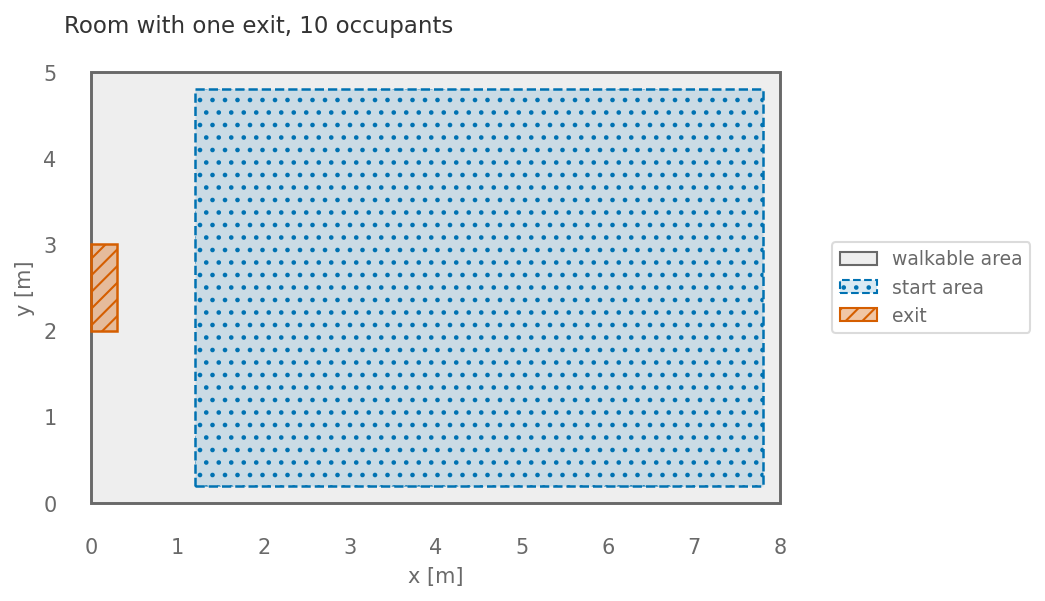

In [8]:
# Scenario geometry from the loaded ZIP.
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(6.4, 4.4))
    handles = vv_draw_scenario(ax, scenario)
    ax.set_title(f"Room with one exit, {vv_agent_count(scenario)} occupants", loc="left")
    ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.02, 0.5))
    plt.show()

In [9]:
starts = []
for agent_id, sub in df.sort_values(['id', 'frame']).groupby('id'):
    x0, y0 = sub.iloc[0][['x', 'y']]
    moved = sub[(sub.x - x0).abs() + (sub.y - y0).abs() > 0.05]
    t = (moved.iloc[0]['frame'] / result.frame_rate) if len(moved) else float('nan')
    starts.append(t)
observed_starts = np.array(starts)
result.cleanup()

1

## Observed vs Analytic Premovement Times

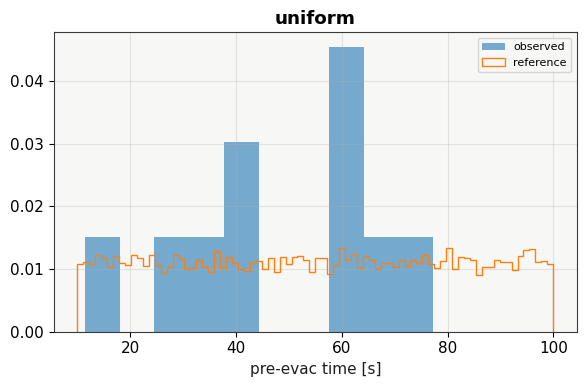

In [10]:
UNIFORM_PARAMS = {"a": 10.0, "b": 100.0}
fig, ax = plt.subplots(figsize=(6, 4))
obs = observed_starts[~np.isnan(observed_starts)]
if len(obs):
    ax.hist(obs, bins=10, density=True, alpha=0.6, label='observed')
ref = create_premovement_distribution("uniform", UNIFORM_PARAMS, seed=1).sample(10000)
ax.hist(ref, bins=80, density=True, histtype='step', label='reference')
ax.set_title('uniform'); ax.set_xlabel('pre-evac time [s]'); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## Acceptance

Each occupant must start within the distribution's support, and observed starts should be consistent with the assigned family (two-sample KS, alpha = 0.05).

In [11]:
from scipy import stats as _stats
ALPHA = 0.05
obs = observed_starts[~np.isnan(observed_starts)]
ref = create_premovement_distribution("uniform", UNIFORM_PARAMS, seed=2).sample(10000)
ks = _stats.ks_2samp(obs, ref) if len(obs) else None
fit = pd.DataFrame([{
    'case': 'uniform', 'n': int(len(obs)),
    'min_s': float(obs.min()) if len(obs) else float('nan'),
    'max_s': float(obs.max()) if len(obs) else float('nan'),
    'ks_p': ks.pvalue if ks else float('nan'),
}])
print(fit)
assert (fit['ks_p'] > ALPHA).all(), fit

      case   n  min_s  max_s      ks_p
0  uniform  10   11.4   77.3  0.273241
